# PCA 주성분 분석 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week14/pca/lab/pca.ipynb)

그림자가 가장 넓게 퍼지는 방향 = 공분산 행렬의 고유벡터.

- **파트 1**: 학생 점수 20명 → 각도별 퍼짐, 고유분해로 PC1 직접 구하기
- **파트 2**: `sklearn` PCA 와 비교, 붓꽃 4 → 2차원 (표준화 전후)
- **파트 3**: 손글씨 숫자 압축 · 복원

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_digits
from sklearn.preprocessing import StandardScaler

## 파트 1. 학생 20명의 (수학, 물리)

In [ ]:
scores = np.array([[95, 92], [35, 47], [73, 76], [61, 59], [62, 62], [65, 68], [42, 55], [65, 64], [57, 57], [99, 99],
                   [71, 66], [63, 62], [64, 70], [59, 63], [54, 56], [63, 67], [74, 58], [65, 71], [80, 74], [65, 56]], float)

def variance_kept(X, deg):
    Xc = X - X.mean(axis=0)
    u = np.array([np.cos(np.radians(deg)), np.sin(np.radians(deg))])
    shadow = Xc @ u                                      # one number per student
    return None  # TODO: shadow spread / total spread

degs = np.arange(0, 181)
kept = [variance_kept(scores, d) for d in degs]
print("math axis:", round(variance_kept(scores, 0) * 100), "%   best:", degs[np.argmax(kept)], "deg,", round(max(kept) * 100), "%")
plt.plot(degs, np.array(kept) * 100); plt.xlabel("direction (degrees)"); plt.ylabel("variance kept (%)"); plt.show()

**예상 결과**

```
math axis: 59 %   best: 39 deg, 95 %
```

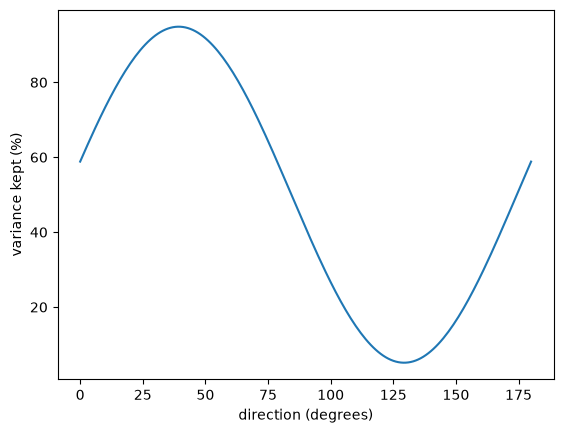

In [ ]:
def my_pca(X):
    Xc = X - X.mean(axis=0)
    S = None  # TODO: covariance matrix
    eigval, eigvec = np.linalg.eigh(S)                   # ascending order
    order = np.argsort(eigval)[::-1]
    eigvec = eigvec[:, order] * np.sign(eigvec[0, order])   # sign is arbitrary: make the first entry positive
    return eigval[order], eigvec, S

eigval, eigvec, S = my_pca(scores)
print("S ="); print(S.round(1))
print("eigenvalues:", eigval.round(1), "  ratio:", (eigval / eigval.sum()).round(3))
print("PC1:", eigvec[:, 0].round(2), "  angle:", round(np.degrees(np.arctan2(eigvec[1, 0], eigvec[0, 0])) % 180), "deg")

**예상 결과**

```
S =
[[217.8 162.8]
 [162.8 152.4]]
eigenvalues: [351.2  19. ]   ratio: [0.949 0.051]
PC1: [0.77 0.63]   angle: 39 deg
```

## 파트 2. sklearn 과 비교 · 붓꽃

In [ ]:
pca = PCA().fit(scores)
print("sklearn ratio:", pca.explained_variance_ratio_.round(3), "  PC1:", pca.components_[0].round(2), "(sign may flip)")

iris = load_iris()
for name, X in [("raw", iris.data), ("standardized", StandardScaler().fit_transform(iris.data))]:
    p = PCA().fit(X)
    print(f"iris {name:12s}: ratio % {(p.explained_variance_ratio_ * 100).round(1)}")

Z = PCA(2).fit_transform(iris.data)
for k, name in enumerate(iris.target_names):
    plt.scatter(*Z[iris.target == k].T, s=20, label=name)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.show()

**예상 결과**

```
sklearn ratio: [0.949 0.051]   PC1: [0.77 0.63] (sign may flip)
iris raw         : ratio % [92.5  5.3  1.7  0.5]
iris standardized: ratio % [73.  22.9  3.7  0.5]
```

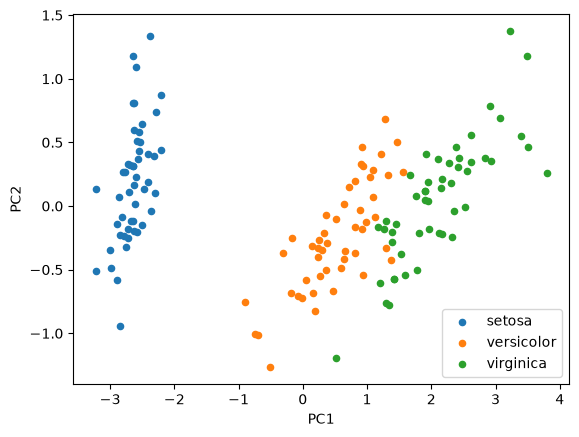

## 파트 3. 손글씨 숫자 압축

한 장 = 8 × 8 = 64칸. 성분 $k$ 개로 줄였다가 (`transform`) 다시 64칸으로 (`inverse_transform`).

In [ ]:
digits = load_digits().data
pca = PCA().fit(digits)
cum = np.cumsum(pca.explained_variance_ratio_)
k90 = None  # TODO: fewest components keeping 90%
print("components for 90%:", k90, "   2 components keep:", round(cum[1] * 100, 1), "%")

def reconstruct(X, k):
    p = PCA(k).fit(X)
    return p.inverse_transform(p.transform(X))

ks = [2, 5, 10, k90, 64]
fig, axs = plt.subplots(1, len(ks) + 1, figsize=(11, 2.4))
axs[0].imshow(digits[0].reshape(8, 8), cmap="gray_r"); axs[0].set_title("original")
for ax, k in zip(axs[1:], ks):
    ax.imshow(reconstruct(digits, k)[0].reshape(8, 8), cmap="gray_r"); ax.set_title(f"k = {k}")
for ax in axs: ax.axis("off")
plt.show()

**예상 결과**

```
components for 90%: 21    2 components keep: 28.5 %
```

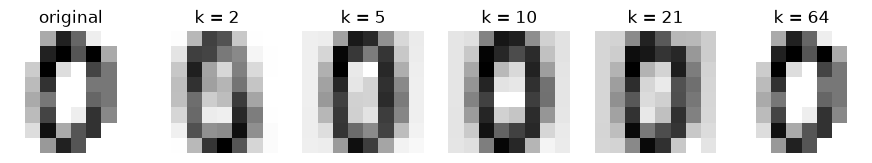

**확인 질문**
1. 파트 1 에서 가장 넓은 방향과 가장 좁은 방향은 몇 도 차이인가? 두 비율의 합은?
2. 파트 2 에서 표준화하면 PC1 비율이 92.5% → 73.0% 로 줄어든 이유는?
3. 파트 3 에서 2 성분만으로 숫자 1,797장을 평면에 그리면 잘 갈라질까? (`PCA(2)` 로 그려 보기 → 다음 시간 t-SNE)
4. (도전) 학생 점수에 '국어' 를 더해 3차원으로 만든다면, 국어가 수학 · 물리와 상관이 없을 때 PC1 은 어떻게 될까?